# Bonus

🎯 84 feature’dan oluşan tam `ML_Houses_dataset.csv` dataset’iyle [buradan ulaşarak](https://d32aokrjazspmn.cloudfront.net/materials/ML_Houses_dataset.csv) serbestçe çalışabilirsiniz!

- Feature’ları inceleyin
- Uygun şekilde preprocess edin ve encode edin
- Feature engineering için beyin fırtınası yapın
- Bunları modelinize ekleyin
- Feature selection uygulayın

👇 Dosyayı yerel olarak `data` klasörüne kaydedin ve buradan içe aktarın.

In [2]:
import os
import pandas as pd
import numpy as np

print("Data klasöründeki dosyalar:")
print(os.listdir("data"))
# Dataset'i yükleyelim
df = pd.read_csv("data/ML_Houses_dataset.csv")

# Dataset'in boyutlarını inceleyelim
print("Dataset boyutu:", df.shape)
print("Satır sayısı:", df.shape[0])
print("Sütun sayısı:", df.shape[1])

# İlk 5 satırı görüntüleyelim
display(df.head())

Data klasöründeki dosyalar:
['ML_Houses_dataset.csv', '.keep']
Dataset boyutu: (1760, 85)
Satır sayısı: 1760
Sütun sayısı: 85


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


ℹ️ Dataset’in açıklamasına mutlaka [buradan](https://drive.google.com/file/d/1qLxeQXufW_-KHOckpUweLPhitzjnP7H3/view?usp=sharing) referans verin.

In [3]:
# Tüm sütun isimlerini görüntüleyelim
print("Sütun isimleri:")
print(df.columns.tolist())

# Veri tiplerini inceleyelim
print("\nVeri tipleri:")
print(df.dtypes.value_counts())

# Sayısal ve kategorik değişkenleri belirleyelim
numeric_cols = df.select_dtypes(include=["number"]).columns
categorical_cols = df.select_dtypes(include=["object", "category"]).columns

print("\nSayısal sütun sayısı:", len(numeric_cols))
print("Kategorik sütun sayısı:", len(categorical_cols))

Sütun isimleri:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'Pesos', 'WallMat', 'RoofSurface', 'ChimneyStyle', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF'

In [4]:
# Eksik değerleri hesaplayalım
missing_values = df.isnull().sum()

# Eksik değer yüzdelerini hesaplayalım
missing_percent = (missing_values / len(df)) * 100

# Sonuçları tablo haline getirelim
missing_df = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percent": missing_percent
})

# Sadece eksik değeri olan sütunları gösterelim
missing_df = missing_df[
    missing_df["Missing_Count"] > 0
].sort_values(by="Missing_Percent", ascending=False)

display(missing_df)

print("Eksik değer içeren sütun sayısı:", len(missing_df))
print("Toplam eksik değer sayısı:", df.isnull().sum().sum())

,Missing_Count,Missing_Percent
WallMat,1755,99.715909
PoolQC,1751,99.488636
MiscFeature,1694,96.250000
Alley,1648,93.636364
Fence,1418,80.568182
MasVnrType,1062,60.340909
FireplaceQu,827,46.988636
LotFrontage,309,17.556818
GarageType,93,5.284091
GarageYrBlt,93,5.284091


Eksik değer içeren sütun sayısı: 22
Toplam eksik değer sayısı: 11180


In [5]:
# Havuz, şömine, garaj ve bodrum ilişkilerini inceleyelim

checks = [
    ("PoolQC", "PoolArea"),
    ("FireplaceQu", "Fireplaces"),
    ("GarageType", "GarageCars"),
    ("BsmtQual", "TotalBsmtSF"),
    ("MasVnrType", "MasVnrArea")
]

for categorical, numerical in checks:
    print(f"\n--- {categorical} / {numerical} ---")

    print(
        df.groupby(
            df[categorical].isna()
        )[numerical].agg(["count", "mean", "min", "max"])
    )


--- PoolQC / PoolArea ---
        count        mean  min  max
PoolQC                             
False       9  564.888889  480  738
True     1751    0.000000    0    0

--- FireplaceQu / Fireplaces ---
             count      mean  min  max
FireplaceQu                           
False          933  1.166131    1    3
True           827  0.000000    0    0

--- GarageType / GarageCars ---
            count      mean  min  max
GarageType                           
False        1667  1.875225    1    4
True           93  0.000000    0    0

--- BsmtQual / TotalBsmtSF ---
          count         mean  min   max
BsmtQual                               
False      1717  1094.029703  105  6110
True         43     0.000000    0     0

--- MasVnrType / MasVnrArea ---
            count        mean  min     max
MasVnrType                                
False         698  261.979943  0.0  1600.0
True         1053    0.899335  0.0   344.0


In [6]:
# MasVnrType eksik değerlerini inceleyelim

missing_mas = df[df["MasVnrType"].isna()]

print("MasVnrType eksik kayıt sayısı:", len(missing_mas))

print(
    "MasVnrType eksik ve MasVnrArea > 0 olan kayıt:",
    (missing_mas["MasVnrArea"] > 0).sum()
)

print(
    "MasVnrType eksik ve MasVnrArea = 0 olan kayıt:",
    (missing_mas["MasVnrArea"] == 0).sum()
)

print(
    "MasVnrType eksik ve MasVnrArea da eksik olan kayıt:",
    missing_mas["MasVnrArea"].isna().sum()
)

# Kaplama alanı olduğu halde tipi eksik olan evleri gösterelim
display(
    missing_mas.loc[
        missing_mas["MasVnrArea"] > 0,
        ["MasVnrType", "MasVnrArea", "SalePrice"]
    ].head(10)
)

MasVnrType eksik kayıt sayısı: 1062
MasVnrType eksik ve MasVnrArea > 0 olan kayıt: 6
MasVnrType eksik ve MasVnrArea = 0 olan kayıt: 1047
MasVnrType eksik ve MasVnrArea da eksik olan kayıt: 9


,MasVnrType,MasVnrArea,SalePrice
624,NaN,288.0,165150
773,NaN,1.0,114500
1230,NaN,1.0,190000
1300,NaN,344.0,225000
1334,NaN,312.0,125000
1737,NaN,1.0,190000


count      1760.000000
mean     182289.685227
std       82143.250734
min       34900.000000
25%      129900.000000
50%      163500.000000
75%      214925.000000
max      755000.000000
Name: SalePrice, dtype: float64

Skewness: 1.9814007327262944


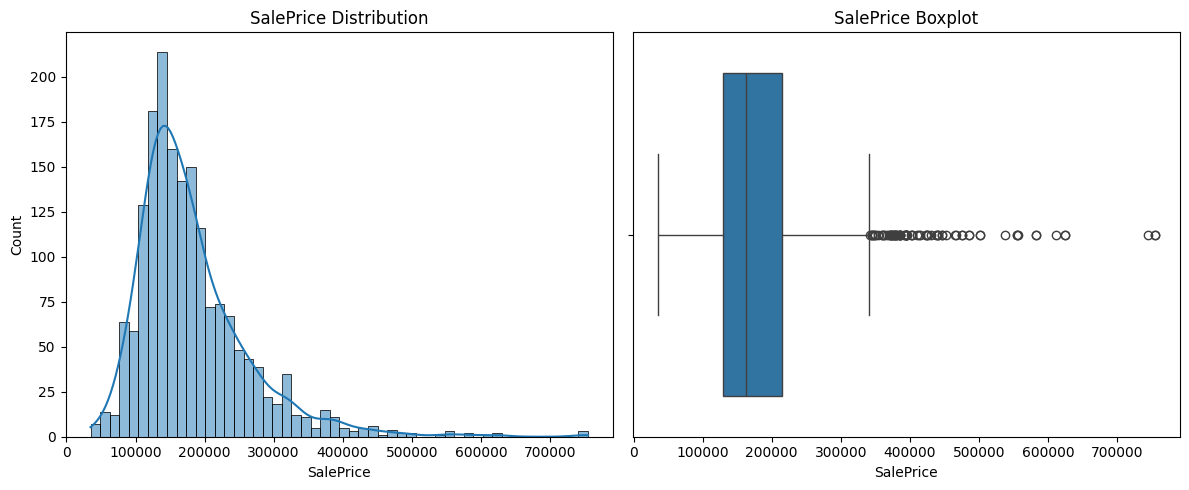

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# SalePrice istatistikleri
print(df["SalePrice"].describe())

print("\nSkewness:", df["SalePrice"].skew())

# Satış fiyatı dağılımı
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df["SalePrice"], kde=True)
plt.title("SalePrice Distribution")

plt.subplot(1, 2, 2)
sns.boxplot(x=df["SalePrice"])
plt.title("SalePrice Boxplot")

plt.tight_layout()
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

# Hedef değişken ve özellikler
X = df.drop(columns=["SalePrice", "Id"])
y = df["SalePrice"]

# Eğitim ve test ayrımı
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nEğitim seti oranı:", len(X_train) / len(X))
print("Test seti oranı:", len(X_test) / len(X))

X_train: (1408, 83)
X_test: (352, 83)
y_train: (1408,)
y_test: (352,)

Eğitim seti oranı: 0.8
Test seti oranı: 0.2


In [9]:
# Eğitim ve test verilerinin kopyalarını oluşturalım
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

# Yokluğu temsil eden kategorik sütunlar
none_cols = [
    "PoolQC",
    "Alley",
    "Fence",
    "MiscFeature",
    "FireplaceQu"
]

# Eğitim ve test setlerinde eksik değerleri dolduralım
for col in none_cols:
    X_train_clean[col] = X_train_clean[col].fillna("None")
    X_test_clean[col] = X_test_clean[col].fillna("None")

# Sonuçları kontrol edelim
print("Doldurma sonrası eksik değerler:")

print(X_train_clean[none_cols].isnull().sum())

print("\nEğitim seti boyutu:", X_train_clean.shape)
print("Test seti boyutu:", X_test_clean.shape)

Doldurma sonrası eksik değerler:
PoolQC         0
Alley          0
Fence          0
MiscFeature    0
FireplaceQu    0
dtype: int64

Eğitim seti boyutu: (1408, 83)
Test seti boyutu: (352, 83)


In [10]:
# Garaj ve bodrum kategorik değişkenleri
garage_cols = [
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond"
]

basement_cols = [
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2"
]

# Eğitim ve test setlerinde işlem yapalım
for data in [X_train_clean, X_test_clean]:

    # Garajı olmayan evler
    no_garage = data["GarageCars"] == 0

    for col in garage_cols:
        data.loc[no_garage, col] = "None"

    # Bodrumu olmayan evler
    no_basement = data["TotalBsmtSF"] == 0

    for col in basement_cols:
        data.loc[no_basement, col] = "None"

# Kalan eksik değerleri kontrol edelim
cols = garage_cols + basement_cols

print("Eğitim setindeki eksik değerler:")
print(X_train_clean[cols].isnull().sum())

print("\nTest setindeki eksik değerler:")
print(X_test_clean[cols].isnull().sum())

Eğitim setindeki eksik değerler:
GarageType      0
GarageFinish    0
GarageQual      0
GarageCond      0
BsmtQual        0
BsmtCond        0
BsmtExposure    1
BsmtFinType1    0
BsmtFinType2    1
dtype: int64

Test setindeki eksik değerler:
GarageType      0
GarageFinish    0
GarageQual      0
GarageCond      0
BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    1
dtype: int64


In [11]:
# Bodrumu olan evlerde kalan eksik kategorik değerler
remaining_basement_cols = [
    "BsmtExposure",
    "BsmtFinType2"
]

for data in [X_train_clean, X_test_clean]:
    for col in remaining_basement_cols:
        data[col] = data[col].fillna("Unknown")

# Kontrol
print("Eğitim setindeki eksik bodrum değerleri:")
print(X_train_clean[basement_cols].isnull().sum())

print("\nTest setindeki eksik bodrum değerleri:")
print(X_test_clean[basement_cols].isnull().sum())

Eğitim setindeki eksik bodrum değerleri:
BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
dtype: int64

Test setindeki eksik bodrum değerleri:
BsmtQual        0
BsmtCond        0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
dtype: int64


In [12]:
for data in [X_train_clean, X_test_clean]:

    # Garaj var mı?
    data["HasGarage"] = (data["GarageCars"] > 0).astype(int)

    # Garajın satış yılındaki yaşı
    data["GarageAge"] = data["YrSold"] - data["GarageYrBlt"]

    # Garajı olmayan evlerde yaş 0
    data.loc[data["HasGarage"] == 0, "GarageAge"] = 0

    # Orijinal GarageYrBlt sütununu çıkar
    data.drop(columns=["GarageYrBlt"], inplace=True)

# Kontrol
print("Eğitim seti:")
print(X_train_clean[["HasGarage", "GarageAge"]].head())

print("\nEksik GarageAge sayısı:")
print("Train:", X_train_clean["GarageAge"].isnull().sum())
print("Test:", X_test_clean["GarageAge"].isnull().sum())

print("\nYeni eğitim seti boyutu:", X_train_clean.shape)

Eğitim seti:
      HasGarage  GarageAge
199           1        5.0
700           1        4.0
526           1       51.0
1716          1       11.0
1605          1       30.0

Eksik GarageAge sayısı:
Train: 0
Test: 0

Yeni eğitim seti boyutu: (1408, 84)


In [13]:
# Mahalle bazında medyan değerleri sadece eğitim setinden hesapla
neighborhood_medians = X_train_clean.groupby(
    "Neighborhood"
)["LotFrontage"].median()

# Eğitim setinin genel medyanı
global_median = X_train_clean["LotFrontage"].median()

# Eğitim ve test setindeki eksik değerleri doldur
for data in [X_train_clean, X_test_clean]:

    data["LotFrontage"] = data["LotFrontage"].fillna(
        data["Neighborhood"].map(neighborhood_medians)
    )

    # Mahalle medyanı bulunamazsa genel medyanı kullan
    data["LotFrontage"] = data["LotFrontage"].fillna(
        global_median
    )

# Sonuçları kontrol et
print("LotFrontage eksik değer kontrolü:")
print("Train:", X_train_clean["LotFrontage"].isnull().sum())
print("Test:", X_test_clean["LotFrontage"].isnull().sum())

print("\nMahalle bazında medyanlar:")
print(neighborhood_medians.sort_values())

LotFrontage eksik değer kontrolü:
Train: 0
Test: 0

Mahalle bazında medyanlar:
Neighborhood
BrDale     21.0
MeadowV    21.0
Blueste    24.0
NPkVill    24.0
Blmngtn    43.0
BrkSide    51.0
SWISU      60.0
IDOTRR     60.0
OldTown    60.0
Edwards    63.0
StoneBr    64.5
Gilbert    65.0
SawyerW    65.5
Veenker    68.0
CollgCr    70.0
Mitchel    71.0
Sawyer     71.0
NAmes      73.0
Somerst    73.5
Crawfor    74.5
NWAmes     80.0
ClearCr    81.0
Timber     83.0
NoRidge    90.0
NridgHt    93.0
Name: LotFrontage, dtype: float64


In [14]:
# MasVnrArea eksik değerlerini eğitim medyanıyla dolduralım
mas_median = X_train_clean["MasVnrArea"].median()

for data in [X_train_clean, X_test_clean]:

    # Alan bilgisi eksik olan kayıtları belirle
    missing_area = data["MasVnrArea"].isna()

    # Eksik alanları eğitim medyanıyla doldur
    data["MasVnrArea"] = data["MasVnrArea"].fillna(mas_median)

    # Kaplama türü eksik ve alanı 0 olan evler
    no_masonry = (
        data["MasVnrType"].isna()
        & (data["MasVnrArea"] == 0)
        & ~missing_area
    )

    data.loc[no_masonry, "MasVnrType"] = "None"

    # Kalan eksik kaplama türlerini Unknown yap
    data["MasVnrType"] = data["MasVnrType"].fillna("Unknown")

# Kontrol
print("MasVnrType eksik değerleri:")
print("Train:", X_train_clean["MasVnrType"].isna().sum())
print("Test:", X_test_clean["MasVnrType"].isna().sum())

print("\nMasVnrArea eksik değerleri:")
print("Train:", X_train_clean["MasVnrArea"].isna().sum())
print("Test:", X_test_clean["MasVnrArea"].isna().sum())

print("\nEğitim setinde MasVnrType dağılımı:")
print(X_train_clean["MasVnrType"].value_counts())

MasVnrType eksik değerleri:
Train: 0
Test: 0

MasVnrArea eksik değerleri:
Train: 0
Test: 0

Eğitim setinde MasVnrType dağılımı:
MasVnrType
None       821
BrkFace    429
Stone      130
BrkCmn      14
Unknown     14
Name: count, dtype: int64


In [15]:
# Kalan eksik değerleri inceleyelim
remaining_missing = X_train_clean.isnull().sum()

print("Eğitim setinde eksik değer kalan sütunlar:")
print(remaining_missing[remaining_missing > 0])

# Özel inceleme yapılacak sütunlar
special_cols = [
    "Pesos",
    "RoofSurface",
    "Electrical",
    "WallMat"
]

for col in special_cols:
    print(f"\n--- {col} ---")

    print("Veri tipi:", X_train_clean[col].dtype)

    print("Eksik değer:", X_train_clean[col].isna().sum())

    print("\nDeğer dağılımı:")
    print(X_train_clean[col].value_counts(dropna=False).head(15))

Eğitim setinde eksik değer kalan sütunlar:
Pesos            11
WallMat        1403
RoofSurface      10
Electrical        1
dtype: int64

--- Pesos ---
Veri tipi: float64
Eksik değer: 11

Değer dağılımı:
Pesos
2800000.0    19
2700000.0    17
3200000.0    14
2900000.0    14
3800000.0    13
2500000.0    13
2300000.0    12
2200000.0    11
3100000.0    11
2600000.0    11
NaN          11
2240000.0    10
2880000.0    10
3600000.0     9
2000000.0     9
Name: count, dtype: int64

--- RoofSurface ---
Veri tipi: float64
Eksik değer: 10

Değer dağılımı:
RoofSurface
NaN       10
3817.0     5
4489.0     4
3349.0     4
2577.0     4
4234.0     4
1847.0     4
2814.0     4
3112.0     4
4525.0     4
4708.0     4
4843.0     3
4141.0     3
4540.0     3
4742.0     3
Name: count, dtype: int64

--- Electrical ---
Veri tipi: object
Eksik değer: 1

Değer dağılımı:
Electrical
SBrkr    1302
FuseA      78
FuseF      23
FuseP       4
NaN         1
Name: count, dtype: int64

--- WallMat ---
Veri tipi: object
Eksik d

In [16]:
# WallMat sütununu çıkaralım
X_train_clean.drop(columns=["WallMat"], inplace=True)
X_test_clean.drop(columns=["WallMat"], inplace=True)

# Electrical: eğitim setindeki en sık görülen değer
electrical_mode = X_train_clean["Electrical"].mode()[0]

# RoofSurface: eğitim setindeki medyan
roof_median = X_train_clean["RoofSurface"].median()

for data in [X_train_clean, X_test_clean]:
    data["Electrical"] = data["Electrical"].fillna(electrical_mode)
    data["RoofSurface"] = data["RoofSurface"].fillna(roof_median)

print("Electrical eksik değerleri:")
print("Train:", X_train_clean["Electrical"].isna().sum())
print("Test:", X_test_clean["Electrical"].isna().sum())

print("\nRoofSurface eksik değerleri:")
print("Train:", X_train_clean["RoofSurface"].isna().sum())
print("Test:", X_test_clean["RoofSurface"].isna().sum())

print("\nEğitim seti boyutu:", X_train_clean.shape)

Electrical eksik değerleri:
Train: 0
Test: 0

RoofSurface eksik değerleri:
Train: 0
Test: 0

Eğitim seti boyutu: (1408, 83)


In [17]:
# Pesos ile SalePrice arasındaki ilişki
pesos_analysis = pd.DataFrame({
    "Pesos": X_train_clean["Pesos"],
    "SalePrice": y_train
}).dropna()

# Korelasyon
correlation = pesos_analysis["Pesos"].corr(
    pesos_analysis["SalePrice"]
)

print("Pesos - SalePrice korelasyonu:", correlation)

# İki değişken arasındaki oran
pesos_analysis["Ratio"] = (
    pesos_analysis["Pesos"] / pesos_analysis["SalePrice"]
)

print("\nOran istatistikleri:")
print(pesos_analysis["Ratio"].describe())

# İlk 10 kayıt
display(pesos_analysis.head(10))

Pesos - SalePrice korelasyonu: 1.0

Oran istatistikleri:
count    1397.0
mean       20.0
std         0.0
min        20.0
25%        20.0
50%        20.0
75%        20.0
max        20.0
Name: Ratio, dtype: float64


,Pesos,SalePrice,Ratio
199,5498000.0,274900,20.0
700,6250000.0,312500,20.0
526,2640000.0,132000,20.0
1716,4126000.0,206300,20.0
1605,2380000.0,119000,20.0
538,3160000.0,158000,20.0
1452,2900000.0,145000,20.0
670,3470000.0,173500,20.0
1110,3760000.0,188000,20.0
575,2370000.0,118500,20.0


In [18]:
# Veri sızıntısına neden olan Pesos sütununu çıkaralım

X_train_clean = X_train_clean.drop(columns=["Pesos"])
X_test_clean = X_test_clean.drop(columns=["Pesos"])

# Kontroller
print("Eğitim seti:", X_train_clean.shape)
print("Test seti:", X_test_clean.shape)

print("\nKalan eksik değerler:")
print("Train:", X_train_clean.isnull().sum().sum())
print("Test:", X_test_clean.isnull().sum().sum())

print("\nPesos sütunu mevcut mu?")
print("Train:", "Pesos" in X_train_clean.columns)
print("Test:", "Pesos" in X_test_clean.columns)

Eğitim seti: (1408, 82)
Test seti: (352, 82)

Kalan eksik değerler:
Train: 0
Test: 0

Pesos sütunu mevcut mu?
Train: False
Test: False


In [19]:
# Feature Engineering

for data in [X_train_clean, X_test_clean]:

    # 1. Evin satış anındaki yaşı
    data["HouseAge"] = (
        data["YrSold"] - data["YearBuilt"]
    )

    # 2. Son tadilattan itibaren geçen yıl
    data["YearsSinceRemodel"] = (
        data["YrSold"] - data["YearRemodAdd"]
    )

    # 3. Toplam alan
    data["TotalSF"] = (
        data["TotalBsmtSF"]
        + data["1stFlrSF"]
        + data["2ndFlrSF"]
    )

    # 4. Toplam banyo sayısı
    data["TotalBathrooms"] = (
        data["FullBath"]
        + 0.5 * data["HalfBath"]
        + data["BsmtFullBath"]
        + 0.5 * data["BsmtHalfBath"]
    )

    # 5. Toplam veranda alanı
    data["TotalPorchSF"] = (
        data["OpenPorchSF"]
        + data["EnclosedPorch"]
        + data["3SsnPorch"]
        + data["ScreenPorch"]
    )

# Yeni feature'ları kontrol edelim
new_features = [
    "HouseAge",
    "YearsSinceRemodel",
    "TotalSF",
    "TotalBathrooms",
    "TotalPorchSF"
]

print("Yeni feature'lar:")
display(X_train_clean[new_features].head())

print("\nEğitim seti:", X_train_clean.shape)
print("Test seti:", X_test_clean.shape)

print("\nYeni feature'lardaki eksik değerler:")
print(X_train_clean[new_features].isnull().sum())

Yeni feature'lar:


,HouseAge,YearsSinceRemodel,TotalSF,TotalBathrooms,TotalPorchSF
199,5,4,3426,3.0,196
700,4,4,3600,3.0,78
526,51,7,1856,1.0,156
1716,11,10,2688,4.0,0
1605,108,58,2228,2.0,242



Eğitim seti: (1408, 87)
Test seti: (352, 87)

Yeni feature'lardaki eksik değerler:
HouseAge             0
YearsSinceRemodel    0
TotalSF              0
TotalBathrooms       0
TotalPorchSF         0
dtype: int64
